# 08 排行榜功能：实时排名、赛季归档与分布式任务调度

## 本章范围与资料来源

第 07 章已经把有效学习行为转成积分明细。本章把这些明细累积成当月排行榜，并在月初保存上一赛季的最终结果。学习主线：**积分入账 → Redis 实时排名 → 榜单接口 → 赛季分表 → XXL-JOB → 分片归档 → 历史查询**。

| 来源 | 本章使用的内容 |
| --- | --- |
| [网盘分享](https://pan.baidu.com/s/1dcVvDI-sWN68Xzcsz1LSAQ?pwd=w7bj)，提取码 `w7bj` | `day08-排行榜功能/讲义/day08-排行榜.pptx`，共 61 页；核对实时榜单、`GET /boards`、按赛季分表、XXL-JOB 架构、动态表名和分页分片；嵌入原 PPT 第 49、57 页 |
| 网盘 `资料/xxl-job/docker命令.txt` | 已读取文本预览：课程使用 `xxl-job-admin:2.3.0`，宿主端口 `28080` 映射容器端口 `8080`，日志挂载 `/data/applogs` |
| [第三方公开转载：Day08-排行榜功能](https://imousse.github.io/cswiki/src/project/college/08-%E6%8E%92%E8%A1%8C%E6%A6%9C%E5%8A%9F%E8%83%BD) | 补充服务代码、ThreadLocal、分页持久化、任务链及两项练习；读取实体截图，核对 `IdType.INPUT` 和非数据库字段。该页面是转载，不能当作已核验的官方最新源码 |
| 网盘配套资料目录 | 确认有 `enums`、`query`、`vo`、`xxl-job`、`points_board.sql`；查询附件为 `PointsBoardQuery.java`，调度目录还有 `xxl-job.sql`。未取得 Java/SQL 附件全文；普通下载出现登录提示 |

阅读日期：2026-10-09。章节根目录显示 `讲义`、`资料`，未见独立作业目录。本文练习范围来自已读转载讲义。

**课件方案**指材料明确给出的实现；**整理示例**是保留主线的简化代码；**补充 / 改进示例**说明并发、重试和恢复条件。未读取的附件不作为源码引用。PPT 的 SQL 拼写、排序方向和部分简化表述在相关单元格中说明。

本 Notebook 全部是 Markdown 单元格，Java、SQL、Redis 命令用于阅读。没有运行课程服务、建表、调度任务或删除数据。图片随 Notebook 内嵌，阅读不依赖下载目录。

## 榜单的两种生命周期

用户需要知道“本月谁学得最多”和“上月最终排第几”。正在变化的榜单要求更新快，结束后的榜单要求结果稳定，两者适合不同的存储方式。

| 对象 | 数据来源 | 存储与查询 | 生命周期 |
| --- | --- | --- | --- |
| 积分明细 | 每次实际入账 | MySQL `points_record` | 可审计、可重建总分 |
| 当前赛季榜单 | 明细中的实际得分增量 | Redis SortedSet | 当前自然月持续更新 |
| 历史赛季榜单 | 已结束月份的最终榜单 | MySQL `points_board_<seasonId>` | 归档完成后稳定查询 |
| 赛季目录 | 赛季 ID、开始与结束日期 | `points_board_season` | 连接页面赛季选择、月份和物理表 |

```text
有效业务事件 → 每日限额与去重 → 保存实际积分明细
                                   ↓ 实际得分
                              当月 Redis ZSet
                                   ↓ 月初归档
                          上赛季 MySQL 独立表
```

**一个自然月是一个赛季**。`202610` 是 Redis Key 中的月份后缀，赛季 ID 是数据库业务编号；二者不能直接互换。月初换用新 Key 即可从零累积，新月开始不要求先删掉旧月 Key。

公开列表只展示前 100 名；“我的排名”独立查询，可以是第 101 名、第 10000 名。归档要保存所有得分用户，才能在历史赛季查询榜外用户的排名。

## 为什么不在每次请求中聚合积分明细

一个用户有多条明细，排行榜需要把同一个月、同一个用户的积分求和，再比较总分。下面是修正后的**整理 SQL**：

```sql
SELECT user_id, SUM(points) AS total_points
FROM points_record
WHERE create_time >= :month_begin
  AND create_time <  :next_month_begin
GROUP BY user_id
ORDER BY total_points DESC, user_id DESC
LIMIT 100;
```

月份用左闭右开区间，避免把下月零点计入上月，也避免依赖“月底最后一微秒”。`create_time` 对应实体创建时间；PPT 表格用 `c_time` 作简写，落地要核对实际表字段。

PPT 的演示语句没有月份过滤，`ORDER BY SUM(points)` 也没有 `DESC`；如果原样执行，会混入其他月份并默认升序。其排名示例还写了 `WHRERE`，并省略从 0 基础计数到第 1 名的转换。

| 方案 | 主要成本 | 适用情况 |
| --- | --- | --- |
| 每请求聚合明细 | 重复扫描、分组、排序 | 数据小、低频统计或核对 |
| 定期离线生成结果 | 周期性计算与结果发布 | 接受几分钟延迟，批量报表 |
| 每次入账更新总分，再用 ZSet 排序 | 常驻 Redis 内存、更新一致性 | 本章实时榜单 |

索引能减少扫描范围，但不会使任意规模的聚合排序免费。第 07 章的明细仍保留，用于审计和榜单重建；实时请求读已经累积好的榜单。

示例 SQL 的同分规则是按数值 user_id 倒序，只用于演示确定排序；它不等同于 Redis 字符串 member 的字典序。若用明细重建与课程完全一致的榜单，应重新写入 ZSet 后按同一规则生成最终名次。

## SortedSet 的榜单模型

SortedSet（ZSet，有序集合）同时保存唯一成员和分数，按分数排序。成员重复写入时修改同一个用户，不会自动增加一行。

| 部分 | 课程含义 | 示例 |
| --- | --- | --- |
| Key | 一个赛季的榜单 | `board:202301`，PPT 中的原值 |
| member | 用户 ID 的字符串形式 | `9527` |
| score | 用户该月实际积分总和 | `25` |

```java
// 整理示例：Key 格式与 PPT 一致
static final String POINTS_BOARD_KEY_PREFIX = "board:";
static final DateTimeFormatter POINTS_BOARD_SUFFIX_FORMATTER =
        DateTimeFormatter.ofPattern("yyyyMM");

String key = POINTS_BOARD_KEY_PREFIX
        + now.format(POINTS_BOARD_SUFFIX_FORMATTER);
```

月份后缀是格式化日期，**不是 Unix 时间戳**。多实例使用相同的业务时区；本项目按月定义赛季时，页面、发分、归档必须使用一致的月份边界。

常见大型 ZSet 用跳表和字典支持有序查找与成员定位；小集合可能采用紧凑编码。更新与查询性能要结合成员数量、编码、请求量和 Redis 版本评估，不能仅凭“百万用户”保证延迟。

## 把实际入账分数累积到榜单

第 07 章已经计算了每日限额。例如今日回答累计 18 分，上限 20 分，新回答原本奖励 5 分，**实际只入账 2 分，榜单也只能加 2 分**。

转载讲义在 `PointsRecordServiceImpl.addPointsRecord` 保存明细后增加一段代码。保留关键步骤的**课件方案**如下：

```java
// realPoints 已经过每日上限裁剪
PointsRecord record = new PointsRecord();
record.setUserId(userId);
record.setPoints(realPoints);
record.setType(type);
save(record);

String key = RedisConstants.POINTS_BOARD_KEY_PREFIX
        + now.format(DateUtils.POINTS_BOARD_SUFFIX_FORMATTER);
redisTemplate.opsForZSet()
        .incrementScore(key, userId.toString(), realPoints);
```

`incrementScore` 对应 `ZINCRBY`；用户尚未出现在榜单时创建成员，否则在原分数上累加。其单条 Redis 命令是原子的。

> 原子累加只保证多次命令不会互相覆盖。重复消费同一条积分事件，仍会重复加分；数据库写入与 Redis 更新也没有因此成为同一个事务。

课件按处理时刻 `now` 选择月份。消息跨月延迟时，需要明确按业务发生时刻还是入账时刻归属赛季；若沿用第 07 章补充的业务日期方案，明细、每日限额和榜单 Key 都使用同一个已确认的归属时间。

## Redis 排名与区间命令

取得总分、个人位置和前 N 名，是三个不同的查询。课程使用倒序，以高分排在前面。

| Redis 命令 | Spring Data Redis | 结果 |
| --- | --- | --- |
| `ZINCRBY key delta member` | `incrementScore` | 累加后的分数 |
| `ZSCORE key member` | `score` | 成员分数；不存在为 null |
| `ZREVRANK key member` | `reverseRank` | 倒序位置，从 0 开始；不存在为 null |
| `ZREVRANGE key start stop WITHSCORES` | `reverseRangeWithScores` | 包含首尾的倒序区间 |
| `ZCARD key` | `zCard` | 总成员数，用于统计或归档核对 |

```redis
ZINCRBY board:202301 20 9628
ZINCRBY board:202301 8 9528
ZINCRBY board:202301 5 9527
ZSCORE board:202301 9527
ZREVRANK board:202301 9527
ZREVRANGE board:202301 0 1 WITHSCORES
```

上述独立示例中，9527 总分 5，倒序索引 2，页面显示第 3 名；`0 1` 返回前两名。Redis 新版也可用 `ZRANGE ... REV WITHSCORES`，课程 Java API 无需因此改名。

有序更新、排名定位一般为 `O(log N)`；按位置取 M 条通常为 `O(log N + M)`。一次读取全部成员仍有传输和内存成本，归档必须分批。

## 同分规则：排序位置与并列排名

“同样 100 分是不是都第 1 名”是产品规则。ZSet 的位置排名会给每个成员不同的位置，不自动产生并列名次。

| 排名规则 | 100、100、80 分的名次 | 实现含义 |
| --- | --- | --- |
| 顺序名次 | 1、2、3 | 课程 `reverseRank + 1`，每个成员一个位置 |
| 竞赛排名 | 1、1、3 | 比自己分数高的人数 + 1 |
| 稠密排名 | 1、1、2 | 比自己高的不同分值数量 + 1 |

同分时，Redis 按 member 的字节字典序排序，倒序读取时同分成员也倒序。字符串 `"9"` 的顺序不能等同于数值 9 与 10 的大小，也不能当作谁先达到分数的证据。课程历史表将顺序名次写入主键，归档应保持相同规则。

**补充**：若规则要求同分时更早达分者优先，应记录达分时间并设计明确的第二排序键；不能把无限增长的用户 ID 或时间戳随意塞进浮点 score。Redis score 使用双精度，整数精确表示范围有上限（`2^53`）。课程 PO/VO 的积分和排名是 `Integer`，转换前也应确认不超出 `int` 范围。

修改排序规则会影响实时榜、分页、归档和历史查询，必须一起修改，不能只替换页面显示的名次。

## 查询接口：GET /boards

一个接口同时查询当前和历史赛季，返回个人信息与公开榜单。以下字段已与 PPT 第 18 页核对。

| 项目 | 定义 |
| --- | --- |
| 请求方式与路径 | `GET /boards` |
| 请求参数 | `pageNo`、`pageSize`、`season` |
| 当前赛季约定 | `season` 缺省或为 `0` |
| 历史赛季约定 | `season` 为已结束赛季的 ID |
| 顶层响应 | `points` 我的积分、`rank` 我的排名、`boardList` 列表 |
| 列表项 | `name` 姓名、`points` 积分、`rank` 排名 |

```http
GET /boards?pageNo=1&pageSize=10&season=0
```

```json
{
  "points": 5,
  "rank": 103,
  "boardList": [
    {"name": "小王", "points": 120, "rank": 1},
    {"name": "小李", "points": 100, "rank": 2}
  ]
}
```

这是字段示例，非固定测试数据；返回没有要求 `total`，不要机械套入通用分页 DTO。`PointsBoardQuery` 是查询条件，`PointsBoardVO` 是响应，`PointsBoardItemVO` 是列表项。

```java
@RestController
@RequiredArgsConstructor
@RequestMapping("/boards")
public class PointsBoardController {
    private final IPointsBoardService pointsBoardService;

    @GetMapping
    public PointsBoardVO queryPointsBoardBySeason(PointsBoardQuery query) {
        return pointsBoardService.queryPointsBoardBySeason(query);
    }
}
```

当前用户 ID 来自服务端登录上下文 `UserContext`，不由查询参数指定。入口应验证 `pageNo >= 1`、`pageSize` 的正数与最大值、`season >= 0`，避免负索引或过大请求。

## 单独查询我的当前积分和排名

当前用户可能不在前 100 名，也可能还没有积分，不能从公开列表反查个人信息。下面为转载中的**课件方案**：

```java
private PointsBoard queryMyCurrentBoard(String key) {
    BoundZSetOperations<String, String> ops = redisTemplate.boundZSetOps(key);
    String userId = UserContext.getUser().toString();
    Double points = ops.score(userId);
    Long rank = ops.reverseRank(userId);

    PointsBoard board = new PointsBoard();
    board.setPoints(points == null ? 0 : points.intValue());
    board.setRank(rank == null ? 0 : rank.intValue() + 1);
    return board;
}
```

`boundZSetOps` 绑定同一个 Key，方便连续操作；不意味着把几条 Redis 命令合并成原子操作。代码的 `intValue()` 依赖积分和用户规模在课程字段范围内。

`rank = 0` 是“无排名”的响应约定，前端显示“暂无排名”，不是实际第 0 名。历史查询查不到记录时也保持相同约定；无积分的用户不需要为了占位全部写入 ZSet。

## 分页查询与前 100 名限制

Redis 区间从 0 开始，页码从 1 开始。第 p 页、每页 s 条，区间为 `[(p - 1) × s, p × s - 1]`，第一条的名次为起始索引 + 1。

下面是**整理示例**，从课程方法抽出按区间读取的公共能力；用 `long` 计算索引，遇到无效元组时不压缩后续名次。

```java
List<PointsBoard> readBoardRange(String key, long from, long to) {
    if (from < 0 || to < from) return Collections.emptyList();
    Set<ZSetOperations.TypedTuple<String>> tuples = redisTemplate.opsForZSet()
            .reverseRangeWithScores(key, from, to);
    if (tuples == null || tuples.isEmpty()) return Collections.emptyList();

    List<PointsBoard> result = new ArrayList<>(tuples.size());
    long position = from;
    for (ZSetOperations.TypedTuple<String> tuple : tuples) {
        long rank = ++position;
        String member = tuple.getValue();
        Double score = tuple.getScore();
        if (member == null || score == null) continue;
        PointsBoard row = new PointsBoard();
        row.setUserId(Long.valueOf(member));
        row.setPoints(score.intValue()); // 已验证为课程范围内的整数
        row.setRank(Math.toIntExact(rank));
        result.add(row);
    }
    return result;
}
```

公开 API 和内部归档使用不同边界：

```java
long from = ((long) pageNo - 1) * pageSize;
long to = from + pageSize - 1;
// 公开榜单：先通过分页参数校验，再限制前 100 名
List<PointsBoard> publicList = from >= 100
        ? Collections.emptyList()
        : readBoardRange(key, from, Math.min(to, 99));

// 归档：不加前 100 名限制，读取全部得分用户
List<PointsBoard> archivePage = readBoardRange(key, from, to);
```

课程 `queryCurrentBoardList(key, pageNo, pageSize)` 未自行截断前 100 名，因为后面归档会复用它。应在公开接口层限制显示，不能把内部查询也截断。

## 赛季路由与批量补充用户姓名

Redis 和历史表都保存用户 ID，页面却需要姓名。先取得榜单，再一次性查询这些用户，避免每个榜单项调用一次用户服务（N+1 调用）。

```java
Set<Long> userIds = list.stream()
        .map(PointsBoard::getUserId).collect(Collectors.toSet());
List<UserDTO> users = userClient.queryUserByIds(userIds);
Map<Long, String> names = new HashMap<>();
if (users != null) {
    for (UserDTO user : users) names.put(user.getId(), user.getName());
}
List<PointsBoardItemVO> items = new ArrayList<>();
for (PointsBoard row : list) {
    PointsBoardItemVO item = new PointsBoardItemVO();
    item.setPoints(row.getPoints());
    item.setRank(row.getRank());
    item.setName(names.getOrDefault(row.getUserId(), "用户信息暂不可用"));
    items.add(item);
}
```

以上是**整理示例**，姓名缺失的占位文本为补充；转载代码直接从 Map 取值，可能得到 null。空榜单直接返回空列表，也不要丢掉已经查到的个人积分和排名。

课件以 `season == null || season == 0` 作为当前榜判断，正数走历史分支。**改进**：先解析并验证赛季；若页面传入了当前赛季的真实 ID，也可以识别为当前榜。未结束、归档未完成、赛季不存在，应有明确返回或错误约定，不能依次尝试拼表名查询。

| 情况 | 应采取的路由 |
| --- | --- |
| 空或 0 | 当前月 Redis |
| 真实 ID 对应当前赛季 | 按接口约定识别当前榜，或明确不支持 |
| 已结束且归档完成 | 对应历史表 |
| 正在归档 | 使用约定的过渡读取或提示，不把半张表当完整榜 |
| 非法 / 不存在 ID | 参数或业务错误 |

历史表没有姓名，因此查到的默认是用户当前姓名。若要保留“当时的姓名”，需要额外快照字段，这不是课件现有表结构的能力。

## 实时榜单的查询一致性

用户看榜单时其他人仍在得分。分别查询 `ZSCORE`、`ZREVRANK` 和列表，得到的可能是几个相邻时刻的状态。

| 场景 | 边界 | 可采用的处理 |
| --- | --- | --- |
| 一次页面请求 | 分数和排名之间有人更新 | 普通实时展示接受短暂变化；严格要求则同一次 Lua 读取 |
| 连续翻页 | 第 1 页和第 2 页之间名次移动 | 可能重复或漏见用户；分页不是稳定快照 |
| 月底发奖 / 最终排名 | 结果需要可复核 | 冻结赛季或生成带版本的最终快照 |
| 历史归档 | 批次之间数据仍变化 | 不允许基于变化的索引分页认定导出完整 |

Pipeline 主要减少网络往返，不自动形成隔离快照。一次 Lua 可以让同一个 Key 的本次读取不被其他命令插入，但无法让后续几十次翻页共享同一快照。

本章实时页面允许排名随积分变化；归档与奖励结算需要更严格的截止规则。把两类需求区分开，才能决定是否增加快照成本。

## 月初归档：保存上赛季，再释放旧榜单

新月已经使用新 Key；旧月 Key 保留上一赛季数据，直到归档成功。原课件给出“读上月榜单 → 动态表名 → 持久化 → 清理 Redis”的流程。

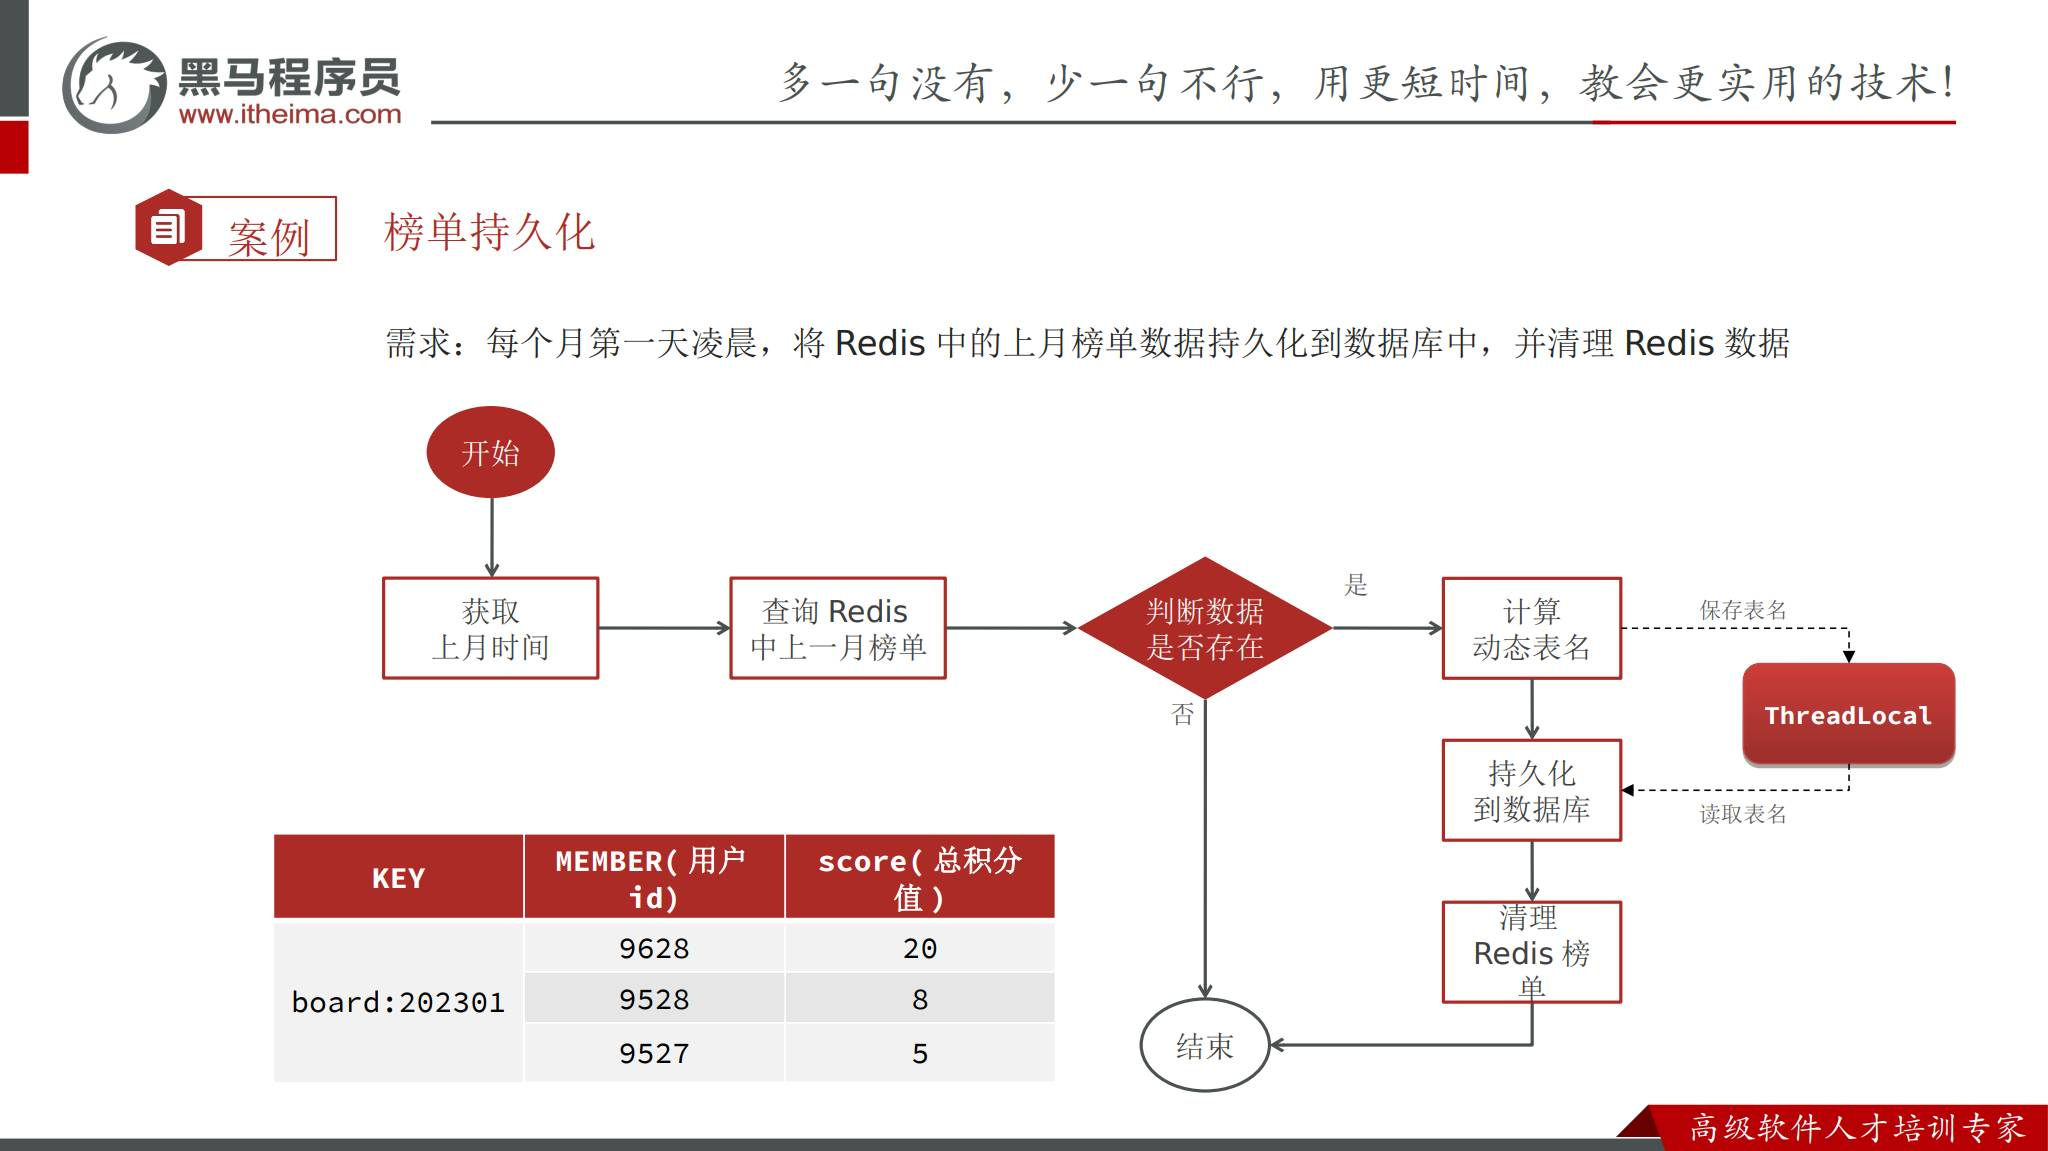

图来源：网盘 `day08-排行榜.pptx` 第 57 页。图中“无数据直接结束”用于课堂流程；实际系统还要分清该赛季确实无人得分，还是 Key 提前过期、被误删、Redis 故障或参数指错月份。

**整理后的顺序**：确定目标赛季与月份 → 等待旧赛季写入结束 → 固定榜单快照 → 建表 → 分批持久化 → 验证完整性 → 发布历史榜 → 清理旧 Key。

本月数据继续正常积累，归档处理上一赛季。新月切换与历史清理是两个动作，清理失败不应影响当前月榜单。

> 迟到消息可能仍属于上月。归档前应有消息排空 / 截止策略；已归档后的补记积分需要修订版本或重建流程，不能悄悄改动正在按排名分页导出的来源。

## 分区、分表、分库与主从的区别

每月都有一份历史榜单，单表会不断累积。先识别瓶颈是行数、行宽、读压力还是单库容量，再选择拆分方式。

| 技术 | 拆分对象 | 谁决定数据去向 | 主要收益与代价 |
| --- | --- | --- | --- |
| 表分区 | 同一逻辑表内的行 | MySQL 分区规则 | 匹配条件时裁剪分区；仍受分区与索引约束 |
| 水平分表 | 相同结构的不同数据行 | 应用 / 路由组件 | 缩小单表；需要选表，跨表聚合更复杂 |
| 垂直分表 | 同一业务的不同字段 | 表设计与关联 | 减少热点行宽；增加关联、写入协调 |
| 垂直分库 | 按业务拆不同的表 | 服务边界 | 分散不同业务负载；跨服务事务更难 |
| 水平分库 | 同类数据按规则分布到多个库 | 分片路由 | 分散容量与写压力；跨片统计与迁移复杂 |
| 主从复制 / 读写分离 | 复制同一数据集 | 复制与访问路由 | 分担读请求并支持故障恢复；有复制延迟 |

课程选择按赛季水平分表：用户通常只看某个赛季，一次只查一张表，暂不需要跨库分片中间件。所有表仍在一个库时，单库的总容量和写入瓶颈没有消失。

**材料校正**：主从保存的是复制数据，不等同于把同一份数据水平切到多台服务器，也不会自动增加主库写能力。字段超过 30 个不是必须垂直分表的硬阈值，应看字段大小、访问模式与索引。高可用也依赖故障检测、切换和数据恢复机制，不能只靠“有从库”推断。

## 表分区的适用条件

分区对外仍是一张表，查询里有分区字段条件时，优化器可能只访问有关分区，这叫分区裁剪。它不保证所有查询更快。

| MySQL 分区形式 | 划分依据 | 赛季场景 |
| --- | --- | --- |
| RANGE | 数值或适当日期表达式的范围 | 按连续赛季 ID / 日期范围划分 |
| LIST | 指定值的集合 | 一个或多个赛季 ID 对应一分区 |
| HASH | 表达式的哈希结果 | 追求数据分散，未必按赛季独立 |
| KEY | MySQL 的键分区算法 | 具体字段支持受版本与规则约束 |

转载称“同赛季放同分区只能用 LIST，赛季无限无法枚举”，这个结论不成立：RANGE 也能按月份划分，LIST 可随时间增加分区，RANGE 可重组预留分区。真正需要评估的是维护成本与数据库限制。

MySQL 分区表要求用于分区表达式的列包含在所有唯一键中，而不是简单地“有任意一个索引就行”。外键、分区数量等限制也要核对版本。示意图的一表一个 `.ibd` 依赖存储引擎与表空间配置，不是所有数据库的通用事实。

课程选分表是因为按赛季选表清晰、应用实现简单；并非 MySQL 无法做月份分区。维护归档也应通过受控数据库操作，不能自行删除底层数据文件。

## 历史表：用主键保存最终名次

历史榜单已经有确定顺序，再查询时不必重新按积分排序。课程将最终排名写入主键 `id`，赛季由表名表达。

```sql
-- 课件字段结构的整理示例：X 替换为经过验证的赛季 ID
CREATE TABLE IF NOT EXISTS `points_board_X` (
    `id` BIGINT NOT NULL AUTO_INCREMENT COMMENT '最终名次',
    `user_id` BIGINT NOT NULL COMMENT '学生id',
    `points` INT NOT NULL COMMENT '积分值',
    PRIMARY KEY (`id`),
    INDEX `idx_user_id` (`user_id`)
) ENGINE=InnoDB
  DEFAULT CHARSET=utf8mb4
  COLLATE=utf8mb4_0900_ai_ci
  ROW_FORMAT=DYNAMIC;
```

`utf8mb4_0900_ai_ci` 是课件采用的 MySQL 8 排序规则；其他数据库版本不能直接照搬。普通 `user_id` 索引用于查询个人记录；若规则是一赛季一用户一行，**改进**可采用唯一索引防止重复用户。

已读转载截图明确使用以下实体注解：

```java
@Data
@TableName("points_board")
public class PointsBoard {
    @TableId(value = "id", type = IdType.INPUT)
    private Long id;
    private Long userId;
    private Integer points;
    @TableField(exist = false)
    private Integer rank;
    @TableField(exist = false)
    private Integer season;
}
```

`rank`、`season` 可作为内存字段，但不写入历史表；表名注解是 `@TableName`，不是讲义文字中的 `@Table`。

**关键**：归档代码显式设置 `id = rank`。不要依赖自增插入顺序计算名次：多个执行器插入顺序不确定，重试也可能产生间隙；不能使用雪花 ID 替代排名。`IdType.INPUT` 表示主键由业务输入，和课程归档代码一致。

## 确定归档月份并查询赛季

月初归档处理的是**上月**。转载文字一度说“创建新赛季表”，但 PPT 第 34、35 页和实际任务代码都查询上月赛季并创建上赛季历史表。

```java
// 课件方案：每月 1 日凌晨 3 点执行
@Scheduled(cron = "0 0 3 1 * ?")
public void createPointsBoardTableOfLastSeason() {
    LocalDateTime time = LocalDateTime.now().minusMonths(1);
    Integer season = seasonService.querySeasonByTime(time);
    if (season == null) return;
    pointsBoardService.createPointsBoardTableBySeason(season);
}
```

赛季查找使用 `beginTime <= time && endTime >= time`。第 07 章赛季表日期字段是 DATE 时，应按日期比较，避免把结束日的零点与当天 03:00 比较后误判：

```java
// 改进示例：基于已确定的目标年月查询，不随每次重试变化
YearMonth targetMonth = YearMonth.of(2026, 9);
LocalDate targetDate = targetMonth.atDay(1);
PointsBoardSeason season = lambdaQuery()
        .le(PointsBoardSeason::getBeginTime, targetDate)
        .ge(PointsBoardSeason::getEndTime, targetDate)
        .one();
if (season == null) throw new IllegalStateException("目标赛季不存在");
```

查询应唯一命中；日期重叠属于赛季配置错误。正式归档时保存 `targetMonth`、`seasonId`、`runId`，失败重试继续同一目标。如果到下个月才重试，不能再次用 `now.minusMonths(1)` 导向另一个赛季。

## 动态建表与表名校验

SQL 参数占位符可以绑定值，但不能将表名绑定为 `#{tableName}`。课程 Mapper 因此用 `${tableName}` 拼接标识符。

```java
// 整理示例：赛季 ID 必须先从合法赛季目录解析
static String pointsBoardTable(long seasonId) {
    if (seasonId <= 0) throw new IllegalArgumentException("非法赛季ID");
    return "points_board_" + seasonId;
}

// Mapper
void createPointsBoardTable(@Param("tableName") String tableName);
```

```xml
<!-- 整理示例：省略其余已展示的表定义 -->
<insert id="createPointsBoardTable">
    CREATE TABLE IF NOT EXISTS `${tableName}` (
        `id` BIGINT NOT NULL AUTO_INCREMENT,
        `user_id` BIGINT NOT NULL,
        `points` INT NOT NULL,
        PRIMARY KEY (`id`),
        INDEX `idx_user_id` (`user_id`)
    ) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4
</insert>
```

表名只由固定前缀与已验证的正整数构造，不接受前端提交任意表名。即使用反引号包围，也不能把未验证的字符串直接放入 `${}`。

转载 Mapper XML 没有 `IF NOT EXISTS`，而 PPT 和讲义 DDL 有；上面的整理版本保留它，便于重试。存在同名表不等于结构正确，仍需检查字段与索引版本。DDL 也不能假定能随普通业务事务一起回滚。

## 从 SpringTask 到统一任务调度

三个学习服务实例各自启用 `@Scheduled`，同一时间会有三个本地触发器。统一调度需要将“什么时候执行、交给谁”与具体业务代码分离。

| 能力 | 本地 SpringTask | 分布式调度平台 |
| --- | --- | --- |
| 触发 | 每个进程按本地规则触发 | 调度中心统一触发 |
| 执行器选择 | 本进程 | 路由到一个实例或分片广播 |
| 任务状态 | 主要依赖应用日志 | 调度日志、执行结果回调 |
| 失败处理 | 自行实现 | 配置重试、超时等，并配合业务幂等 |
| 任务关系 | 应用自己组织 | 子任务 / 工作流能力，仍需业务完整性控制 |

课程比较 Quartz、XXL-JOB、SchedulerX、PowerJob，并选用 XXL-JOB。选型时看是否需要管理控制台、分片、工作流、云托管、运维成本和已有设施，不能以课件中的旧市场判断当作当前结论。

Quartz 是调度库，也能通过 JDBC JobStore 等方式实现集群协调；“没有开箱即用的统一业务控制台”不等于“不能集群”。框架能力随版本和配套产品变化。

集中调度降低重复触发的概率，但网络超时、重试、进程退出仍可能导致任务重复执行。**业务幂等**（重复执行得到相同结果）需要任务自己实现。

## XXL-JOB 的调度中心与执行器

XXL-JOB 分为独立的 Admin 调度中心和嵌入业务服务的执行器。实际归档 SQL、Redis 读取运行在学习服务中。

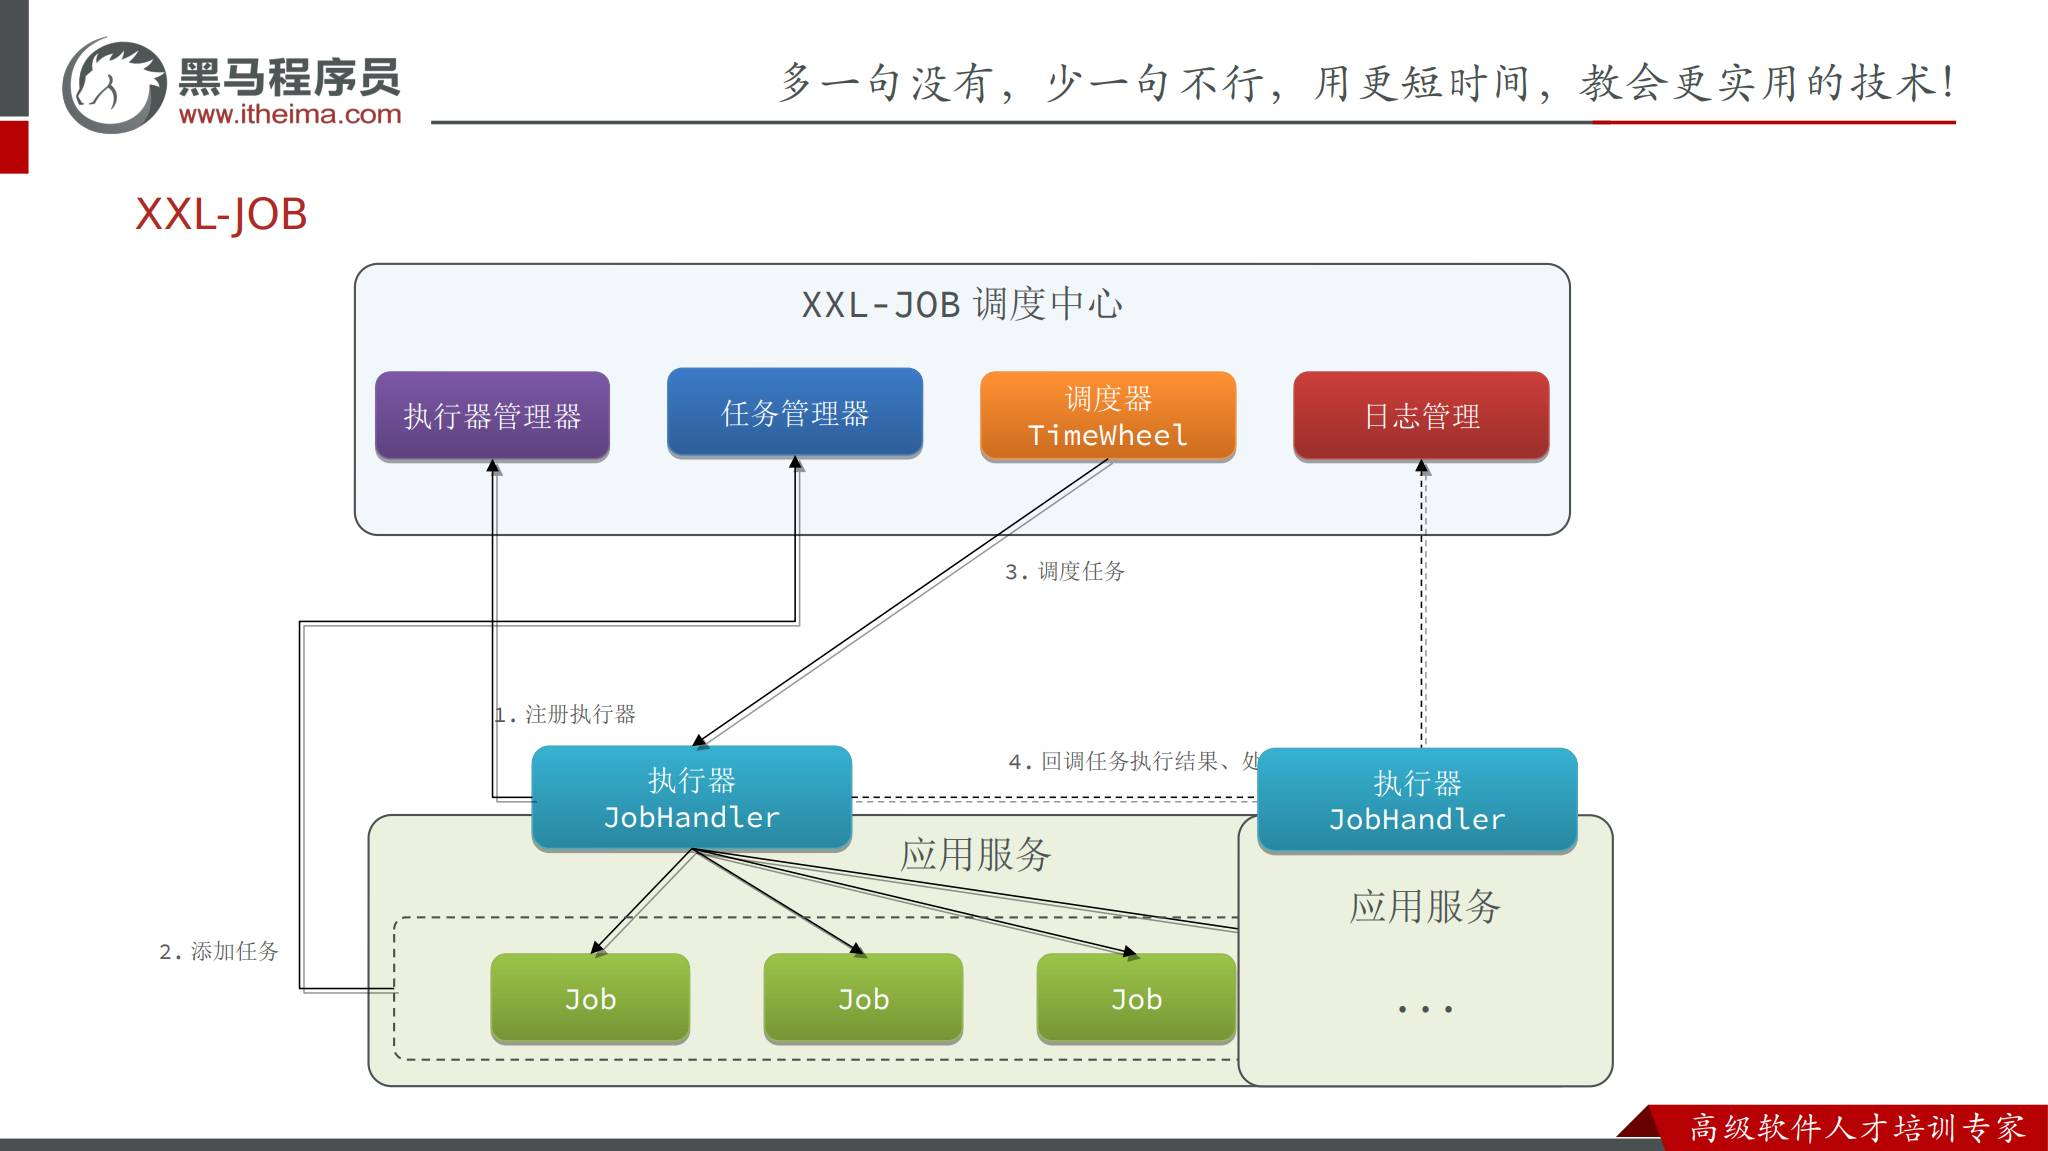

图来源：网盘 `day08-排行榜.pptx` 第 49 页，体现课程版本的架构示意。

| 组件 | 责任 |
| --- | --- |
| 调度中心 | 管理任务与执行器、按计划和路由发起调度、接收结果 |
| 执行器 | 注册地址，接收调度，执行本地 JobHandler，提供执行日志 |
| JobHandler | 一个具名业务任务，如创建表、保存榜单、清理旧 Key |
| 调度数据库 | 存配置、注册、调度日志等控制数据 |

典型过程：执行器注册 → 管理员配置任务 → 调度中心发起执行 → 执行器运行 → 回调结果。调度中心能发起任务，前提是它能够访问执行器公布的地址与端口；应用能访问 Admin 只是一个方向。

## 调度中心部署资料与控制表

课程虚拟机预装了调度中心，也提供独立部署所需 SQL 与 Docker 说明。部署逻辑是“初始化匹配版本的控制表 → 配置数据库与访问参数 → 启动 Admin → 确认执行器网络可达”。本章只整理资料。

| 已读文本中的配置 | 含义 |
| --- | --- |
| `xuxueli/xxl-job-admin:2.3.0` | 课程 Admin 镜像版本，不代表当前最新版本 |
| `28080:8080` | 宿主端口 28080 转到容器内部 8080 |
| 日志挂载 `/data/applogs` | 保存调度日志，避免随容器丢失 |
| JDBC URL 与数据库账号 | 连接 Admin 控制数据库，不是榜单表 |

PPT 第 50 页展示 `8880:8080`，已读 `docker命令.txt` 与转载示例使用 `28080:8080`。这只是宿主端口选择不同，实际访问地址以环境配置为准。课程演示的密码与令牌不作为新环境配置值。

转载说明的 8 张控制表：

| 表 | 作用 |
| --- | --- |
| `xxl_job_lock` | 调度协调锁 |
| `xxl_job_group` | 执行器分组信息 |
| `xxl_job_info` | 任务配置、调度与执行参数 |
| `xxl_job_log` | 调度和执行历史 |
| `xxl_job_log_report` | 日志统计报表 |
| `xxl_job_logglue` | GLUE 脚本版本历史 |
| `xxl_job_registry` | 在线注册信息 |
| `xxl_job_user` | 控制台用户 |

这些表记录的是调度状态，不替代业务归档清单、榜单数据或去重记录。Admin、core 依赖和初始化 SQL 的版本要兼容；不能把课程旧镜像与任意新版 SQL 混搭。

## 学习服务集成执行器

学习服务引入 `xxl-job-core`，由项目公共模块提供自动装配，并读取 Nacos 的共享配置。

```xml
<!-- 课件依赖；版本由项目依赖管理统一指定 -->
<dependency>
    <groupId>com.xuxueli</groupId>
    <artifactId>xxl-job-core</artifactId>
</dependency>
```

```yaml
# 整理节选：加入原有 shared-configs，而不是覆盖其他共享配置
spring:
  application:
    name: learning-service
  cloud:
    nacos:
      config:
        shared-configs:
          - data-id: shared-xxljob.yaml
            refresh: false
```

底层装配的是 `XxlJobSpringExecutor`，核心配置含义如下：

| 配置 / setter | 含义与核对项 |
| --- | --- |
| `setAdminAddresses` | 调度中心地址，包含实际访问路径 |
| `setAppname` | 执行器名；与控制台登记的 AppName 一致 |
| `setIp`、`setPort` | 执行器发布地址；Admin 必须能访问 |
| `setAccessToken` | 调度中心与执行器一致的认证令牌 |
| `setLogPath` | 执行日志目录 |
| `setLogRetentionDays` | 执行日志保留期限 |

自动探测 IP 在容器、NAT、多网卡环境下可能得到不可达地址；端口默认值也要核对所用版本。学习服务 HTTP 端口 8090 不代表执行器 RPC 端口一定是 8090。

转载已提供 `tj-common` 的自动装配，不要再重复声明冲突的执行器 Bean。共享配置中的注释“共享 mq 配置”是复制残留，`shared-xxljob.yaml` 实际属于任务调度。

## 定义 JobHandler 与控制台任务

Bean 模式用 `@XxlJob` 注册一个有名字的任务。PPT 第 52 页用 `createTableJob` 演示：

```java
@Component
@RequiredArgsConstructor
public class PointsBoardPersistentHandler {
    @XxlJob("createTableJob")
    public void createTableJob() {
        // 确定目标赛季并调用建表服务
    }
}
```

注解类名是 `XxlJob`，不是转载文字中的 `XXLJob`。控制台的 JobHandler 必须与注解字符串完全匹配，Java 方法名本身不替代注册名。迁移后由 XXL-JOB 调度该任务，避免保留第二套 `@Scheduled` 触发。

控制台配置顺序：登记学习服务执行器 → 确认实例在线 → 新建 BEAN 任务 → 指定 JobHandler、执行参数和路由 → 设置 Cron / 子任务关系 → 查看调度与执行日志。

| 配置 | 本章用途 |
| --- | --- |
| Cron | 月初启动归档；课程本地任务示例为 `0 0 3 1 * ?` |
| 任务参数 | 改进方案传目标月份、赛季 ID、归档 runId |
| 路由策略 | 建表 / 清理通常选单实例；持久化可分片广播 |
| 阻塞策略 | 控制同一执行器上重复触发时如何处理 |
| 超时与重试 | 约束长任务并恢复失败，依赖幂等设计 |
| 日志与告警 | 查看失败页、目标表、分片、重试次数 |

课程的“执行一次”用于手动触发验证；它会真实运行任务。阅读笔记不需要触发，调度成功也不等于业务数据已经完整。

## 路由策略与分片广播

多个执行器在线时，调度中心需要选择执行目标。课程介绍以下策略：

| 策略 | 行为 | 适用判断 |
| --- | --- | --- |
| FIRST / LAST | 固定选择第一个 / 最后一个地址 | 简单固定路由，依赖列表顺序 |
| ROUND | 轮询选择 | 分散不同次触发 |
| RANDOM | 随机选择 | 不要求固定实例 |
| CONSISTENT_HASH | 按任务哈希路由 | 保持相对稳定的目标分配 |
| LFU / LRU | 最少使用 / 最近最久未使用优先 | 按框架记录的使用情况分配 |
| FAILOVER | 心跳检测后选择可用目标 | 提升调度可达性 |
| BUSYOVER | 检测空闲目标后选择 | 避开忙碌执行器 |
| SHARDING_BROADCAST | 向在线实例发送分片参数 | 各实例处理不同子集 |

LFU、LRU 在控制台 / 枚举中常显示完整名称 `LEAST_FREQUENTLY_USED`、`LEAST_RECENTLY_USED`。具体行为以课程版本为准。

**广播不等于自动拆数据**。框架只告知“我是第几片，一共有几片”；业务代码必须据此分配页。若所有执行器仍从第 1 页逐页导出，就会重复处理。

故障转移检测的是调度目标状态，不证明已经提交的业务操作只执行过一次。超时重试之前仍要考虑旧执行器可能正在运行或已经写入成功。

## MyBatis-Plus 动态表名插件

`PointsBoard` 的 `@TableName("points_board")` 是固定逻辑表名，历史数据却在 `points_board_1`、`points_board_2`。动态表名插件在执行 SQL 前把逻辑名替换为目标物理表。

```text
归档任务 / 历史查询确定赛季
        ↓
ThreadLocal 保存 points_board_7
        ↓
MyBatis-Plus 生成访问 points_board 的 SQL
        ↓
DynamicTableNameInnerInterceptor 替换表名
        ↓
访问 points_board_7
```

转载使用课程旧版的构造方式：

```java
Map<String, TableNameHandler> handlers = new HashMap<>(1);
handlers.put("points_board", (sql, name) -> TableInfoContext.getInfo());
return new DynamicTableNameInnerInterceptor(handlers);
```

**版本适配示例**：某些新版使用统一 `setTableNameHandler`，此时必须限制目标表，并验证上下文：

```java
DynamicTableNameInnerInterceptor interceptor =
        new DynamicTableNameInnerInterceptor();
interceptor.setTableNameHandler((sql, tableName) -> {
    if (!"points_board".equals(tableName)) return tableName;
    String physical = TableInfoContext.getInfo();
    if (physical == null || !physical.matches("points_board_[1-9][0-9]*")) {
        throw new IllegalStateException("历史榜单表上下文缺失或非法");
    }
    return physical;
});
```

两种配置按项目 MyBatis-Plus 版本二选一，不要混用无法编译的 API。历史路径缺少表名时直接失败，防止意外写入基表。

课程 `tj-common` 已拥有 `MybatisPlusInterceptor`，应把动态表名拦截器加入原有链，并做可选注入，避免其他未定义该插件的服务报错。另建一套配置可能使已有分页等插件失效；动态表名等 SQL 转换通常应在分页处理之前，具体次序核对依赖版本。

## ThreadLocal 传表名与线程复用

业务方法确定表名，插件由框架调用，难以直接传业务参数。ThreadLocal 让同一线程上的两段代码访问同一份上下文，但不会自动跨线程共享。

```java
public final class TableInfoContext {
    private static final ThreadLocal<String> TL = new ThreadLocal<>();
    public static void setInfo(String tableName) { TL.set(tableName); }
    public static String getInfo() { return TL.get(); }
    public static void remove() { TL.remove(); }
}
```

任务线程和请求线程来自线程池，会被下一个任务复用。转载在正常流程末尾 `remove()`；中途 SQL 抛异常会跳过清理。下面是必要的**改进**：

```java
String table = pointsBoardTable(verifiedSeasonId);
TableInfoContext.setInfo(table);
try {
    // 所有访问该赛季榜单表的操作
    pointsBoardService.saveBatch(rows);
} finally {
    TableInfoContext.remove();
}
```

例如归档 9 月失败后线程接着查询 8 月，遗留表名会造成读错表或写错表。`finally` 同时处理正常与异常退出。

每个分片线程独立设置与清理；提交到另一个异步线程后，需在那里重新设置已验证的上下文。存在嵌套调用时，要设计保存并恢复旧上下文的作用域工具，而不是无条件删除外层值。共享静态字符串不具备线程隔离，不能替代 ThreadLocal。

## 单执行器分页持久化

榜单用户多时，一次全部读取会造成内存与写库压力。课程按页读取 Redis、将名次写入 `id`、批量保存，直到读到空页。

下面是带异常清理的**整理示例**，保留课程单片逻辑。`targetMonth` 与 `seasonId` 已在任务开始前确定；来源在导出期间必须稳定。

```java
void persistSeason(YearMonth targetMonth, int seasonId) {
    String key = "board:" + targetMonth.format(DateTimeFormatter.ofPattern("yyyyMM"));
    TableInfoContext.setInfo(pointsBoardTable(seasonId));
    try {
        int pageNo = 1;
        int pageSize = 1000; // 课件单执行器示例
        while (true) {
            List<PointsBoard> rows = pointsBoardService
                    .queryCurrentBoardList(key, pageNo, pageSize);
            if (rows == null || rows.isEmpty()) break;
            for (PointsBoard row : rows) {
                row.setId(row.getRank().longValue());
                row.setRank(null);
            }
            if (!pointsBoardService.saveBatch(rows)) {
                throw new IllegalStateException("榜单批次保存失败");
            }
            pageNo++;
        }
    } finally {
        TableInfoContext.remove();
    }
}
```

`queryCurrentBoardList` 的名字表示查询 Redis 结构，并不要求 Key 一定是当前月份；归档传入的是上月 Key。把它公开到 `IPointsBoardService`，供任务复用。

这个示例未实现重试去重、断点记录、完整性核验和清理授权，不能直接称为生产级归档。每页独立提交比较容易控制事务大小；某一页失败时，前几页可能已提交，整个 while 循环不是自动全局事务。

## 按页轮转分片的计算方法

三个执行器不能同时导出全部页。课程将每一页看作一张牌，轮流发给各执行器，形成互不相同的页集合。

| 执行器 | `shardIndex` | 起始页 | 后续页 |
| --- | --- | --- | --- |
| 第 1 个 | 0 | 1 | 4、7、10、13…… |
| 第 2 个 | 1 | 2 | 5、8、11、14…… |
| 第 3 个 | 2 | 3 | 6、9、12、15…… |

公式：

```text
pageNo = shardIndex + 1
step = shardTotal
每次：pageNo += step
```

PPT 第 60 页用第 1、2、3 个执行器讲解；Java API 的分片索引从 0 开始，所以代码必须 `+1`。给固定的总分片数 T，任意页 p 归属于 `(p - 1) % T`，覆盖所有页且每页只分到一片。

页 4 不意味着第 4 名：每页 1000 条时，页 4 对应索引 3000～3999、名次 3001～4000。名次始终由全局索引决定，不能在每个分片内从 1 重新编号。

这个划分成立的前提：本次运行的来源、每页大小和总分片数一致。集群扩缩容后重跑，不能未经协调沿用旧的局部进度。

## 分片 JobHandler 的核心实现

XXL-JOB 在分片广播时提供编号与总数量。下面是**整理节选**，展示课程页分配与写入主线，省略已说明的目标解析、上下文和核验：

```java
@XxlJob("savePointsBoard2DB")
public void savePointsBoard2DB() {
    int index = XxlJobHelper.getShardIndex();
    int total = XxlJobHelper.getShardTotal();
    if (total <= 0 || index < 0 || index >= total) {
        throw new IllegalStateException("分片参数非法");
    }
    // 同一 runId 指定同一个 targetMonth、seasonId、sourceKey
    int pageNo = index + 1;
    int pageSize = 1000;
    while (true) {
        List<PointsBoard> rows = pointsBoardService
                .queryCurrentBoardList(sourceKey, pageNo, pageSize);
        if (rows == null || rows.isEmpty()) break;
        for (PointsBoard row : rows) {
            row.setId(row.getRank().longValue());
            row.setRank(null);
        }
        if (!pointsBoardService.saveBatch(rows)) {
            throw new IllegalStateException("分片写入失败");
        }
        pageNo = Math.addExact(pageNo, total);
    }
}
```

转载分片演示用 `pageSize = 10`，用于观察页分配；单片代码是 1000。这里展示 1000 是整理选择，不是固定最佳批量。真实批量根据 Redis 返回大小、DB 吞吐和事务时间压测决定。

广播模式下每一片都需要 `try/finally` 清理 ThreadLocal。应记录分片编号、总片数、页码、来源版本和写入行数；不能只输出一句“任务成功”。

若最后一片没有分到任何页，也要区分“正常零行”与来源缺失。单片成功只是该子集处理成功，尚不能发布整份历史榜。

## 可重试归档：固定来源、幂等写入与断点

任务第 5 页写完后网络断开，调度平台可能从头重试。课程 `saveBatch` 使用普通插入，重复的排名主键会冲突，因此有重试按钮不代表数据能安全重试。

**改进方案**以一次归档运行作为恢复单位：

| 信息 | 用途 |
| --- | --- |
| `runId`、目标赛季与月份 | 所有任务和重试指向同一个目标 |
| 来源快照 / 版本、预期成员数 | 分页期间不会漂移，知道应导出多少行 |
| 页大小、总分片数 | 保持分片分工一致 |
| 已提交页与分片回执 | 断点恢复、判断全片完成 |
| 写入行数、分值合计 / 摘要 | 检查遗漏、重复和内容不一致 |
| 运行状态 | 控制发布与清理资格 |

对**不可变快照**，排名主键固定，可以设计“同一 `(runId, pageNo)` 只提交一次”或校验内容一致的幂等写入。提交页数据与提交页进度应在同一数据库事务内；否则会出现页写了却没记进度，或记了进度但没写数据。

不能把 `saveOrUpdateBatch` 当作万能去重：如果来源改变，原第 1 名的 `id=1` 已变成另一个用户，覆盖旧行可能掩盖混合版本。带 `user_id` 唯一约束的写入也需要同时保证排名与用户对应关系不变。

若旧月允许补记而顺序改变，按来源版本重建新表 / 新结果，校验后再切换发布。不要对一个会变化的 ZSet 一边分页、一边追加积分、一边宣称没有遗漏。

## 任务链与所有分片完成的边界

课件把任务拆成创建表、持久化、清理三个 Job，便于分别重试。转载控制台示例 ID 为 `10 → 12 → 13`，这些是该环境生成的任务 ID，换环境不能照搬。

```text
创建历史表（单实例）
        ↓
持久化榜单（分片广播）
        ↓ 所有分片回执齐全 + 数据核验通过
发布归档完成状态
        ↓
清理上赛季 Redis Key（单实例）
```

配置子任务可以表达“父任务成功后触发后续任务”。**但不能把它直接当作分片聚合屏障**：一个执行回调成功，不证明其他分片已经完成。课程只演示了任务链，没有提供业务级全片核验机制。

**补充设计**：为同一 `runId` 固定 `expectedShardTotal`，每片成功后持久记录唯一回执；汇总任务确认全部回执、目标表计数与来源数据核验通过，才把状态从 `WRITING` 改为 `COMMITTED`。清理任务只接受 `COMMITTED` 的同一个 runId，并且自身幂等。

| 状态示例 | 允许的动作 |
| --- | --- |
| PREPARED | 建表、固定来源 |
| WRITING | 分片写入与恢复 |
| VERIFYING | 检查全片完成及完整性 |
| COMMITTED | 对外发布历史榜、允许受控清理 |
| CLEANED | 已释放旧 Key，重复清理可确认完成 |

此状态设计是工程补充，不是课件现有实现。它解决的是“整份榜单完整”，与调度平台的“这次 Handler 返回成功”不同。

## 清理旧榜单：UNLINK 的作用与条件

历史榜单已经持久化并通过核验后，才释放旧赛季 Redis 内存。转载任务使用：

```java
@XxlJob("clearPointsBoardFromRedis")
public void clearPointsBoardFromRedis() {
    LocalDateTime time = LocalDateTime.now().minusMonths(1);
    String key = RedisConstants.POINTS_BOARD_KEY_PREFIX
            + time.format(DateUtils.POINTS_BOARD_SUFFIX_FORMATTER);
    redisTemplate.unlink(key);
}
```

这是**课件方案**；正式实现应使用已确认归档目标，避免跨月重试删错 Key。`UNLINK` 将 Key 从可见键空间移除，并把主要内存回收工作交给后台；它减少大 Key 同步释放的阻塞，不提供撤销或恢复能力。

**改进逻辑示例**：

```text
读取 runId → 校验目标月份早于当前月
           → 确认状态 COMMITTED、全部分片成功、目标表完整
           → 确认没有旧赛季写入仍在进行
           → unlink 该运行记录中的 sourceKey
           → 记录 CLEANED
```

清理失败可重试，不需要重新生成已经发布的历史榜。返回“Key 已不存在”也要结合归档状态判断：它可能是重复清理成功，也可能是提前丢失。旧 Key 的过期时间应覆盖归档与恢复窗口，不能在归档尚未成功时自动到期。

PPT 的早期流程图还写“清空积分明细和榜单”。明细是审计与重建依据，应按后面的迁移练习保留历史，不能为月度清零直接清空明细主表。

## 明细与榜单双写的一致性

课程先保存 MySQL 明细，再更新 Redis。两步之间失败会导致“明细有分，榜单没分”；消费重试又可能重复入账或重复加榜单分数。

| 故障点 | 可能结果 | 改进方向 |
| --- | --- | --- |
| MySQL 成功、Redis 更新失败 | 总分少算 | 可靠事件补投 / 从明细重建 |
| Redis 成功、数据库事务回滚 | 榜单多算 | 提交后投影、核对修复 |
| 同一事件重复投递 | 重复加分 | 入账去重 + 榜单投影去重 |
| 归档时仍有上月事件 | 历史来源变化 | 截止规则、消息排空、版本修订 |

承接第 07 章的**补充方案**：在数据库事务中写明细与 Outbox 事件（待投递记录），事件携带唯一 `eventId`、实际得分 `actualPoints`、明确赛季。提交后把事件投影到 Redis，消费者按事件去重。

```text
事务：入账去重 → 额度确认 → 明细 + Outbox
提交后：发布已入账事件 → 原子去重 + ZINCRBY → 确认消费
```

“先查询是否处理过，再 ZINCRBY”仍有竞争；去重标记与累加应在同一个 Lua 操作中完成。Redis Cluster 中相关 Key 必须在同一个槽，例如补充设计 `board:{202610}`、`board:events:{202610}`；这与课程 `board:202610` 的 Key 格式不同，采用时整体迁移。

去重记录的保留时间需要覆盖重投范围，并考虑 Redis 丢数据后分数和去重标记可能不一致。MySQL 明细是恢复依据，可按月份重新聚合构建新榜单；不要向一个已有榜单反复重放所有增量却不清理或校验版本。仅增加 `@Transactional` 不能使 Redis 与 MySQL 共享本地事务。

## 练习一：补齐历史榜单查询

转载课堂方法 `queryMyHistoryBoard`、`queryHistoryBoardList` 是 TODO。本节给出**练习整理示例**，不是已读取的附件实现。

先解析合法、已完成归档的赛季并设置表名；个人记录按 `user_id` 查，公开列表按主键名次范围查。两个查询完成后清理上下文。

```java
TableInfoContext.setInfo(pointsBoardTable(verifiedSeasonId));
try {
    PointsBoard mine = lambdaQuery()
            .eq(PointsBoard::getUserId, UserContext.getUser())
            .one();
    if (mine != null) mine.setRank(Math.toIntExact(mine.getId()));

    long from = ((long) pageNo - 1) * pageSize;
    long lastRank = Math.min(from + pageSize, 100);
    List<PointsBoard> rows = from >= 100
            ? Collections.emptyList()
            : lambdaQuery()
                .ge(PointsBoard::getId, from + 1)
                .le(PointsBoard::getId, lastRank)
                .orderByAsc(PointsBoard::getId)
                .list();
    for (PointsBoard row : rows) row.setRank(Math.toIntExact(row.getId()));
    // mine 的 points/rank → 顶层 VO；rows → 批量查姓名 → boardList
    // mine 不存在：points=0，rank=0；列表为空：boardList=[]
} finally {
    TableInfoContext.remove();
}
```

该查询依赖历史 `id` 是最终顺序名次且归档完整。以主键范围分页，无需每次重新按积分排序；如果系统允许不连续名次或另有 ID 语义，就应换用与该模型一致的分页方式。

| 核对项 | 期望 |
| --- | --- |
| 未进前 100 的历史用户 | 仍返回个人总分与全局名次 |
| 同分用户 | 与该赛季冻结时的顺序一致 |
| 带正数赛季 ID 的请求 | 路由到匹配的物理表 |
| 归档中 / 表不存在 | 按约定处理，不能默认为零人榜 |
| 数据库查询抛异常 | ThreadLocal 必须清理 |

课程 `user_id` 是普通索引，若出现重复用户，`.one()` 会暴露数据问题；不要随便加 `LIMIT 1` 隐藏重复归档。

## 练习二：按赛季迁移积分明细

明细行数比榜单更多，课程练习要求每月初迁移上赛季明细：当前赛季保留在 `points_record`，历史赛季保存到 `points_record_<seasonId>`。

```text
points_record                 当前月以及尚未完成迁移的旧记录
points_record_1               第 1 赛季明细
points_record_2               第 2 赛季明细
points_board_1                第 1 赛季最终榜单
points_board_2                第 2 赛季最终榜单
```

**补充的安全完成路线**：确定旧月日期范围与截止点 → 建结构一致的目标表 → 按稳定的明细 ID 分批复制 → 记录已复制批次 → 核对 ID 集、行数和积分合计 → 按已确认复制的 ID 分批清理来源 → 发布查询路由。

```sql
-- 阅读示例：table 名称已验证，字段应按真实结构显式列出
SELECT id, user_id, type, points, create_time
FROM points_record
WHERE create_time >= :month_begin
  AND create_time <  :next_month_begin
  AND id > :last_id
ORDER BY id
LIMIT :batch_size;
```

保留原明细 ID，用目标主键支持重复复制检测。分页游标 `last_id` 表示本批已经确认处理到的主键；若允许延迟插入或事件时间回填，仍需要截止点与补迁策略，不能仅凭游标宣称全部完成。

积分撤销、消息补记、查询过渡期也需要明确读写路由。删除范围只能是已经核实迁移成功的旧记录；不要 `TRUNCATE points_record`，否则会连同新赛季数据一起清空。正式迁移需要可审计的批次状态与恢复方案，课堂练习没有给出完整迁移器。

## 榜单扩展：按积分范围分桶

转载提出把超大 ZSet 按积分范围分到多个 Key，例如 0～100、101～200、201～300。这是扩展思路，不是本章已经实现的功能。

同一个用户只在一个桶内。假设高分排前，其全局顺序名次为：

```text
全局名次 = 所有更高分桶的用户数之和 + 桶内倒序索引 + 1
```

| 需要新增的能力 | 原因 |
| --- | --- |
| 用户到桶的定位 | 个人查询要知道所在 Key |
| 跨桶迁移 | 得分从 99 到 104，需要从旧桶移出并进入新桶 |
| 桶人数的一致性 | 重复、漏删会直接算错全局排名 |
| 边界、超上限桶与同分规则 | 分数超过最高示例区间仍要有去处 |
| 跨桶分页 / Top100 合并 | 页面不一定只读一个桶 |
| 快照与恢复 | 统计人数和桶内名次要有一致版本 |

跨 Key 更新在 Redis Cluster 中涉及槽约束；把所有桶放同槽虽便于原子操作，也可能仍压在同一节点上。分桶减小单 Key，但不会自动解决热点节点与分布式一致性。

先评估单 ZSet 的内存、更新延迟、查询量、归档耗时和实例资源。课堂项目选择一个月一个 ZSet，在规模证据支持前没有必要加入复杂分桶。

## 材料差异与实现核对项

复现课程时，以下差异会直接影响结果，应按业务规则和实际依赖修正。

| 材料中的简化 / 差异 | 本章采用的处理 |
| --- | --- |
| 聚合 SQL 未倒序、未限定月份；`WHRERE` 拼写错误 | 整理为月份区间、`DESC`；排名区分位置与并列规则 |
| 前 100 名需求，公共 Redis 查询却无限制 | 公开 API 截断到 99 索引；归档保留全量查询 |
| 历史字段“名次只记录前100”的旧注释 | 不作为归档限制；代码导出全部用户 |
| “用自增 ID 就是排名” | 显式 `id=rank`，`IdType.INPUT`，不依赖插入顺序 |
| 建表 DDL 有 IF NOT EXISTS，Mapper XML 没有 | 整理版本保留，并核对已有表结构 |
| 月初建“新表”的文字 | 实际处理上月赛季历史表 |
| PPT Admin 宿主端口 8880，文本 28080 | 已读配套文本为 28080，以部署配置为准 |
| `@XXLJob`、`@Table` 文字简写 | 使用实际 `@XxlJob`、`@TableName` |
| ThreadLocal 只在正常结束 remove | 所有路径使用 finally |
| 清理子任务紧跟分片导出 | 增加全片成功、完整性核验与发布状态 |
| 单片1000、分片10条的页大小 | 视为不同演示参数，同一运行必须统一 |
| 每次任务重新计算上月 | 固定目标年月与 runId，重试不漂移 |

动态表名构造 API、插件次序、执行器默认端口与调度回调行为都依赖版本；本章不把未获取的项目依赖与附件全文伪装成已核验结果。

## 业务验证场景

下面是实现后应验证的业务结果，不是已连接课程系统执行的测试。

| 场景 | 预期 |
| --- | --- |
| 新用户首次实际获得 5 分，再获得 3 分 | 同一 member，总分 8 |
| 回答上限只剩 2 分，新奖励 5 分 | 明细与榜单均增加 2 |
| 完全无积分用户 | 个人积分 0、无排名；列表不强行占位 |
| 我的名次为 101 | 返回个人第 101；公开列表最多前 100 |
| 第 10 页每页 10 条、再查第 11 页 | 第 10 页至 100 名，第 11 页公开列表为空 |
| 两个用户同分 | 顺序遵守 Redis member 比较规则，归档保持一致 |
| 月份切换 | 新 Key 从零积累，旧 Key 在归档前保留 |
| 历史赛季最后一天 | 日期比较仍能正确定位赛季 |
| 三片导出 15 页 | 分工为1/4/7/10/13、2/5/8/11/14、3/6/9/12/15 |
| 中间页失败后重试 | 已确认页不重复产生结果，失败页可恢复 |
| 只完成一个分片 | 不发布完整历史榜，不清理 Redis |
| ThreadLocal 中途异常 | 线程复用后不会残留旧表名 |
| 上月 MQ 事件晚到 | 按确定的截止 / 修订策略处理，不混入新月份 |
| SQL 写入成功、Redis 更新失败 | 可由可靠事件或明细重建修复 |
| 归档 Key 提前消失 | 报告缺失，不能将其视为正常空赛季 |
| 明细迁移中已有新月数据 | 只迁移目标旧月，当前月数据保留 |

核验不仅看行数：还要确认每个用户的分数、最终名次与同一个来源版本一致，尤其覆盖并列分数和归档重试。

## 常见问题的定位顺序

| 现象 | 优先检查 |
| --- | --- |
| 排名从 0 开始 | 是否漏了 `reverseRank + 1`；null 是否正确映射“无排名” |
| 积分多于明细 | 是否使用请求奖励而不是 realPoints；事件是否重复累加 |
| 积分少于明细 | 双写失败、错误月份、投影积压、Key 丢失 |
| 第 2 页名次又从 1 开始 | 是否忘了全局起始索引 |
| 导出只有 100 人 | 公共 API 的前 100 限制是否污染归档方法 |
| 历史榜名次像雪花 ID | 主键策略与 `id=rank` 是否一致 |
| 表名变成 null / 查错赛季 | 赛季解析、插件配置、上下文设置及 finally |
| 多实例导出冲突 | 是否选分片广播，并用 index+1、total 跨度 |
| 后续插件失效 | 是否覆盖了 tj-common 已有 MyBatis-Plus 配置 |
| 执行器一直不在线 / 调度不可达 | AppName、Admin 地址、发布 IP、执行器端口与令牌 |
| 清理后历史榜缺人 | 全片完成屏障、来源变化、归档核验是否缺失 |

先对齐目标赛季与来源版本，再判断排名或分页错误；混用两个月的数据时，即使每条命令都成功也无法得到正确榜单。

## 面试提示

**面试提示**：回答“排行榜怎么做”时，先说明一个自然月一个赛季。当前榜单用 Redis ZSet，member 是用户 ID，score 是该月实际入账总分；入账后累加，个人排名用倒序位置 +1，公开列表分页展示前 100。个人排名独立查，因此榜外用户仍能看到自己名次。同分采用课程的顺序排名，不等于并列排名。

历史榜单按赛季存 MySQL 独立表，显式把最终名次写入主键，按名次读取无需重新排序。XXL-JOB 在月初创建上赛季表、导出旧榜单并清理旧 Key；导出分片的起始页是 `index+1`，页跨度是 `total`。

接着说明可靠性：固定归档月份与来源快照，分批写库并记录断点，重复运行幂等，ThreadLocal 在 finally 清理；所有分片成功且完整性核验通过后才发布和清理。子任务链表达执行关系，不能替代全片完成检查。

若追问双写一致性，说明 MySQL 明细是审计与恢复依据，可以事务内写 Outbox，再用带事件去重的 Redis 投影更新榜单。若追问容量，先给出内存与延迟压测结果，再讨论分桶、跨桶迁移和全局排名成本，不承诺某个人数下必然足够。